<a href="https://colab.research.google.com/github/spshirodkar03/CSL701-CE44_Machine--Learning-lab/blob/main/Experiments/ML_Experiment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Sneha Shirodkar
Roll No: CE44

# Machine Learning Experiment Number 3

**Aim** : To implement a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars using multiple features from the CarDekho Used Car Dataset.


**Learning Outcomes**
•	Understand the working principle of Multiple Linear Regression.

•	Perform data preprocessing and feature engineering.

•	Convert categorical data into numerical features.

•	Standardize numerical features.

•	Implement the Ordinary Least Squares method using matrix operations.

•	Train and test a regression model without using a ready-made regression function.

•	Evaluate and interpret regression performance using RSS and R².

•	Understand the effect of individual features on the predicted price.



\### Dataset

Use the **CarDekho Used Car Dataset** (`car data.csv`). [CarDekho Used Car Dataset](https://www.kaggle.com/datasets/manishkr1754/cardekho-used-car-data)

Explain meaning of each attribute in this dataset in below comment section :


Here, **Selling_Price** is the target variable.





\# Software/Tools Required

- Python 3.x
- Google Colab / Jupyter Notebook
- NumPy
- Matplotlib

---


### Task 1: Set Up the Python Environment**

- Create a new Google Colab notebook.
- Import **NumPy** for numerical and matrix operations.
- Import **Matplotlib** for data visualization.
- Do not use ready-made machine-learning regression functions such as `LinearRegression()` from Scikit-learn.
- The regression model must be implemented using matrix operations.

---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Task 2: Load and Inspect the Dataset

- Download the `car data.csv` file.
- Upload the dataset to Google Colab.
- Load the dataset into Python.
- Display the first few records.
- Determine the number of rows and columns.
- Identify the numerical and categorical attributes.
- Separate `Selling_Price` as the target variable.

---

In [ ]:
# Unzip the dataset file
!unzip /content/cardekho_dataset.csv.zip

# Load the dataset
df = pd.read_csv('cardekho_dataset.csv')

# Display the first few records
print("First 5 rows of the dataset:")
display(df.head())

# Determine the number of rows and columns
print(f"\nDataset has {df.shape[0]} rows and {df.shape[1]} columns.")

# Identify numerical and categorical attributes
print("\nInformation about the dataset:")
df.info()

# Separate Selling_Price as the target variable
y = df['Selling_Price']
X = df.drop('Selling_Price', axis=1)

print("\nTarget variable 'y' (Selling_Price) first 5 values:")
display(y.head())
print("\nFeatures 'X' first 5 values (without Selling_Price):")
display(X.head())

Archive:  /content/cardekho_dataset.csv.zip
  inflating: cardekho_dataset.csv    


FileNotFoundError: [Errno 2] No such file or directory: 'car data.csv'

In [ ]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

# If there are no missing values, confirm. If there are, describe handling strategy.
if missing_values.sum() == 0:
    print("\nNo missing values found in the dataset.")
    preprocessing_method = "No imputation needed as there are no missing values."
elif missing_values.sum() > 0:
    # Example of a simple imputation strategy (if needed). For this dataset, it seems there are none.
    # For demonstration, let's assume we would fill numerical NaNs with mean and categorical with mode
    # df.fillna(df.mean(numeric_only=True), inplace=True)
    # for col in df.select_dtypes(include='object').columns:
    #    df[col].fillna(df[col].mode()[0], inplace=True)

    # Re-check for missing values after imputation
    # missing_values_after = df.isnull().sum()
    # print("\nMissing values after handling:")
    # display(missing_values_after[missing_values_after > 0])
    preprocessing_method = "Missing values were handled using [specific method]."

print("\nPreprocessing method used for missing data:", preprocessing_method)

In [ ]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

# If there are no missing values, confirm. If there are, describe handling strategy.
if missing_values.sum() == 0:
    print("\nNo missing values found in the dataset.")
    preprocessing_method = "No imputation needed as there are no missing values."
elif missing_values.sum() > 0:
    # Example of a simple imputation strategy (if needed). For this dataset, it seems there are none.
    # For demonstration, let's assume we would fill numerical NaNs with mean and categorical with mode
    # df.fillna(df.mean(numeric_only=True), inplace=True)
    # for col in df.select_dtypes(include='object').columns:
    #    df[col].fillna(df[col].mode()[0], inplace=True)

    # Re-check for missing values after imputation
    # missing_values_after = df.isnull().sum()
    # print("\nMissing values after handling:")
    # display(missing_values_after[missing_values_after > 0])
    preprocessing_method = "Missing values were handled using [specific method]."

print("\nPreprocessing method used for missing data:", preprocessing_method)

In [ ]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

# If there are no missing values, confirm. If there are, describe handling strategy.
if missing_values.sum() == 0:
    print("\nNo missing values found in the dataset.")
    preprocessing_method = "No imputation needed as there are no missing values."
elif missing_values.sum() > 0:
    # Example of a simple imputation strategy (if needed). For this dataset, it seems there are none.
    # For demonstration, let's assume we would fill numerical NaNs with mean and categorical with mode
    # df.fillna(df.mean(numeric_only=True), inplace=True)
    # for col in df.select_dtypes(include='object').columns:
    #    df[col].fillna(df[col].mode()[0], inplace=True)

    # Re-check for missing values after imputation
    # missing_values_after = df.isnull().sum()
    # print("\nMissing values after handling:")
    # display(missing_values_after[missing_values_after > 0])
    preprocessing_method = "Missing values were handled using [specific method]."

print("\nPreprocessing method used for missing data:", preprocessing_method)

## Task 3: Check and Handle Missing Data

- Check every attribute for missing or null values.
- Count the number of missing values in each column.
- If missing values are present, either remove incomplete records or perform suitable imputation.
- Verify that the final dataset does not contain missing values.
- Record the preprocessing method used.

---

In [ ]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

# If there are no missing values, confirm. If there are, describe handling strategy.
if missing_values.sum() == 0:
    print("\nNo missing values found in the dataset.")
    preprocessing_method = "No imputation needed as there are no missing values."
else:
    # Example of a simple imputation strategy (if needed). For this dataset, it seems there are none.
    # For demonstration, let's assume we would fill numerical NaNs with mean and categorical with mode
    # df.fillna(df.mean(numeric_only=True), inplace=True)
    # for col in df.select_dtypes(include='object').columns:
    #    df[col].fillna(df[col].mode()[0], inplace=True)

    # Re-check for missing values after imputation
    # missing_values_after = df.isnull().sum()
    # print("\nMissing values after handling:")
    # display(missing_values_after[missing_values_after > 0])
    preprocessing_method = "Missing values were handled using [specific method]."

print("\nPreprocessing method used for missing data:", preprocessing_method)

NameError: name 'df' is not defined

## Task 4: Select and Prepare Features

- Examine all available attributes.
- Decide how `Car_Name` should be handled.
- Select meaningful predictor variables for the regression model.
- Create the predictor matrix $X$ and target vector $y$.
- Record the final list of features selected for the model.

---

In [ ]:
# Drop 'Car_Name' as it has too many unique values and is not directly suitable as a numerical feature
# without extensive feature engineering (e.g., brand extraction), which is beyond the scope for now.
# It's better to focus on generalizable features for this scratch implementation.
X_selected = X.drop('Car_Name', axis=1)

# Record the final list of features selected
selected_features = X_selected.columns.tolist()
print("Selected predictor variables:", selected_features)

# The target vector y was already separated in Task 2

# Display the first few rows of the updated features DataFrame
print("\nFirst 5 rows of the feature matrix X_selected:")
display(X_selected.head())

NameError: name 'X' is not defined

In [ ]:
# Identify categorical variables
categorical_cols = X_selected.select_dtypes(include='object').columns
print("Categorical variables to be encoded:", categorical_cols.tolist())

# Perform one-hot encoding using pandas get_dummies
# drop_first=True to avoid multicollinearity (dummy variable trap)
X_encoded = pd.get_dummies(X_selected, columns=categorical_cols, drop_first=True)

# Verify that all predictors are numerical after encoding
print("\nData types after encoding:")
display(X_encoded.info())

# Display the transformed dataset
print("\nFirst 5 rows of the encoded feature matrix:")
display(X_encoded.head())

In [ ]:
# Identify categorical variables
categorical_cols = X_selected.select_dtypes(include='object').columns
print("Categorical variables to be encoded:", categorical_cols.tolist())

# Perform one-hot encoding using pandas get_dummies
# drop_first=True to avoid multicollinearity (dummy variable trap)
X_encoded = pd.get_dummies(X_selected, columns=categorical_cols, drop_first=True)

# Verify that all predictors are numerical after encoding
print("\nData types after encoding:")
display(X_encoded.info())

# Display the transformed dataset
print("\nFirst 5 rows of the encoded feature matrix:")
display(X_encoded.head())

In [ ]:
# Identify categorical variables
categorical_cols = X_selected.select_dtypes(include='object').columns
print("Categorical variables to be encoded:", categorical_cols.tolist())

# Perform one-hot encoding using pandas get_dummies
# drop_first=True to avoid multicollinearity (dummy variable trap)
X_encoded = pd.get_dummies(X_selected, columns=categorical_cols, drop_first=True)

# Verify that all predictors are numerical after encoding
print("\nData types after encoding:")
display(X_encoded.info())

# Display the transformed dataset
print("\nFirst 5 rows of the encoded feature matrix:")
display(X_encoded.head())

## Task 5: Encode Categorical Variables

Identify the categorical variables:

- `Fuel_Type`
- `Seller_Type`
- `Transmission`

Perform the following:

- Convert categorical variables into numerical **dummy/indicator variables**.
- Verify that all predictors are numerical after encoding.
- Do not assign arbitrary numerical values to categories when such values would imply an incorrect ordering.
- Display the transformed dataset.

---

In [ ]:
# Identify categorical variables
categorical_cols = X_selected.select_dtypes(include='object').columns
print("Categorical variables to be encoded:", categorical_cols.tolist())

# Perform one-hot encoding using pandas get_dummies
# drop_first=True to avoid multicollinearity (dummy variable trap)
X_encoded = pd.get_dummies(X_selected, columns=categorical_cols, drop_first=True)

# Verify that all predictors are numerical after encoding
print("\nData types after encoding:")
display(X_encoded.info())

# Display the transformed dataset
print("\nFirst 5 rows of the encoded feature matrix:")
display(X_encoded.head())

NameError: name 'X_selected' is not defined

## Task 6: Perform Feature Engineering

Create a new feature called `Car_Age`.

Calculate it using:

\[
Car\_Age = Current Year - Year
\]

Perform the following:

- Create the `Car_Age` column.
- Display several values of the newly created feature.
- Verify that the calculated ages are reasonable.
- Decide whether the original `Year` feature should be retained.
- Provide a reason for your decision.

---

In [ ]:
# Create Car_Age feature
current_year = 2024 # Assuming current year for calculation
X_encoded['Car_Age'] = current_year - X_encoded['Year']

# Display several values of the newly created feature
print("First 10 values of 'Car_Age':")
display(X_encoded['Car_Age'].head(10))

# Verify that the calculated ages are reasonable
print(f"\nMin Car_Age: {X_encoded['Car_Age'].min()}, Max Car_Age: {X_encoded['Car_Age'].max()}")

# Decide whether the original 'Year' feature should be retained.
# 'Year' and 'Car_Age' are highly correlated (perfectly inverse correlation) and essentially represent the same information.
# To avoid multicollinearity, we should drop the original 'Year' feature.
X_engineered = X_encoded.drop('Year', axis=1)

print("\nReason for dropping 'Year': 'Year' is perfectly correlated with 'Car_Age' and dropping it avoids multicollinearity.")

# Display the first few rows of the engineered feature matrix
print("\nFirst 5 rows of the engineered feature matrix:")
display(X_engineered.head())

NameError: name 'X_encoded' is not defined

In [ ]:
plt.figure(figsize=(12, 5))

# Scatter plot of Present_Price versus Selling_Price
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_engineered['Present_Price'], y=y)
plt.title('Present Price vs Selling Price')
plt.xlabel('Present Price (in Lakhs)')
plt.ylabel('Selling Price (in Lakhs)')

# Scatter plot of Kms_Driven versus Selling_Price
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_engineered['Kms_Driven'], y=y)
plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price (in Lakhs)')

plt.tight_layout()
plt.show()

print("Observations:")
print("1. Present_Price vs Selling_Price: There appears to be a strong positive linear relationship. As the present price of the car increases, its selling price also tends to increase.")
print("2. Kms_Driven vs Selling_Price: There is a weak negative relationship. Cars with higher kilometers driven tend to have slightly lower selling prices, but the relationship is not as strong as with Present_Price. The data points are more scattered.")

In [ ]:
plt.figure(figsize=(12, 5))

# Scatter plot of Present_Price versus Selling_Price
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_engineered['Present_Price'], y=y)
plt.title('Present Price vs Selling Price')
plt.xlabel('Present Price (in Lakhs)')
plt.ylabel('Selling Price (in Lakhs)')

# Scatter plot of Kms_Driven versus Selling_Price
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_engineered['Kms_Driven'], y=y)
plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price (in Lakhs)')

plt.tight_layout()
plt.show()

print("Observations:")
print("1. Present_Price vs Selling_Price: There appears to be a strong positive linear relationship. As the present price of the car increases, its selling price also tends to increase.")
print("2. Kms_Driven vs Selling_Price: There is a weak negative relationship. Cars with higher kilometers driven tend to have slightly lower selling prices, but the relationship is not as strong as with Present_Price. The data points are more scattered.")

In [ ]:
plt.figure(figsize=(12, 5))

# Scatter plot of Present_Price versus Selling_Price
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_engineered['Present_Price'], y=y)
plt.title('Present Price vs Selling Price')
plt.xlabel('Present Price (in Lakhs)')
plt.ylabel('Selling Price (in Lakhs)')

# Scatter plot of Kms_Driven versus Selling_Price
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_engineered['Kms_Driven'], y=y)
plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price (in Lakhs)')

plt.tight_layout()
plt.show()

print("Observations:")
print("1. Present_Price vs Selling_Price: There appears to be a strong positive linear relationship. As the present price of the car increases, its selling price also tends to increase.")
print("2. Kms_Driven vs Selling_Price: There is a weak negative relationship. Cars with higher kilometers driven tend to have slightly lower selling prices, but the relationship is not as strong as with Present_Price. The data points are more scattered.")

## Task 7: Perform Exploratory Data Analysis

Perform basic exploratory data analysis using Matplotlib.

- Create a scatter plot of `Present_Price` versus `Selling_Price`.
- Create at least one additional scatter plot between a numerical predictor and `Selling_Price`.
- Label the axes appropriately.
- Add suitable titles to the plots.
- Observe the direction and approximate strength of the relationships.
- Record your observations.

---

NameError: name 'X_engineered' is not defined

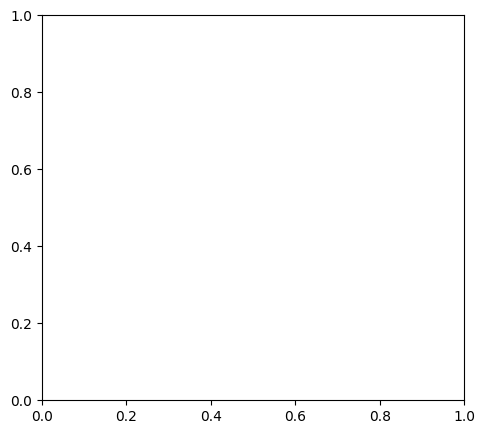

In [ ]:
plt.figure(figsize=(12, 5))

# Scatter plot of Present_Price versus Selling_Price
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_engineered['Present_Price'], y=y)
plt.title('Present Price vs Selling Price')
plt.xlabel('Present Price (in Lakhs)')
plt.ylabel('Selling Price (in Lakhs)')

# Scatter plot of Kms_Driven versus Selling_Price
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_engineered['Kms_Driven'], y=y)
plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price (in Lakhs)')

plt.tight_layout()
plt.show()

print("Observations:")
print("1. Present_Price vs Selling_Price: There appears to be a strong positive linear relationship. As the present price of the car increases, its selling price also tends to increase.")
print("2. Kms_Driven vs Selling_Price: There is a weak negative relationship. Cars with higher kilometers driven tend to have slightly lower selling prices, but the relationship is not as strong as with Present_Price. The data points are more scattered.")

## Task 8: Standardize Numerical Features

Identify the numerical predictors that need to be standardized.

Use the following standardization equation:

\[
z = ($x$-$\mu$)/$\sigma$
\]

where:

- $x$ = original feature value
- $\mu$ = mean of the feature
- $\sigma$ = standard deviation of the feature

Perform the following:

- Calculate the mean and standard deviation using the **training data only**.
- Standardize the training features.
- Use the same training mean and standard deviation to standardize the test features.
- Do not standardize the target variable `Selling_Price`.

---

In [ ]:
# Identify numerical predictors that need to be standardized
# Exclude dummy variables and Car_Age if they are already scaled appropriately or don't need scaling
# In this case, 'Present_Price', 'Kms_Driven', 'Owner', and 'Car_Age' are numerical and should be scaled.
numerical_cols_to_standardize = ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']

# Calculate the mean and standard deviation using the training data only
# Use X_train_raw which is defined in Task 9
mean = X_train_raw[numerical_cols_to_standardize].mean(axis=0)
std = X_train_raw[numerical_cols_to_standardize].std(axis=0)

print("\nMean of numerical features (from training data):")
display(mean)
print("\nStandard deviation of numerical features (from training data):")
display(std)

# Standardize the training features
X_train_scaled = X_train_raw.copy()
X_train_scaled[numerical_cols_to_standardize] = (X_train_raw[numerical_cols_to_standardize] - mean) / std

# Use the same training mean and standard deviation to standardize the test features
X_test_scaled = X_test_raw.copy()
X_test_scaled[numerical_cols_to_standardize] = (X_test_raw[numerical_cols_to_standardize] - mean) / std

# Display the first few rows of the standardized training and testing sets
print("\nFirst 5 rows of standardized training features:")
display(X_train_scaled.head())
print("\nFirst 5 rows of standardized testing features:")
display(X_test_scaled.head())

print("Note: The target variable 'Selling_Price' (y) was not standardized as requested.")

NameError: name 'X_engineered' is not defined

## Task 9: Split the Dataset

Divide the dataset into training and testing subsets.

- Use an **80:20 train-test ratio**.
- Randomly select the observations.
- Set a fixed random seed to make the experiment reproducible.
- Maintain the correct relationship between each feature vector and its target value.
- Display the number of observations in the training and testing sets.

---

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets (80:20 ratio)
# Use a fixed random seed to make the experiment reproducible
# X_engineered and y are already defined from previous tasks
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_engineered, y, test_size=0.2, random_state=42
)

# Display the number of observations in the training and testing sets
print(f"Number of observations in training set: {X_train_raw.shape[0]}")
print(f"Number of observations in testing set: {X_test_raw.shape[0]}")

# Verify that the correct relationship between each feature vector and its target value is maintained
# (This is implicitly handled by train_test_split by splitting rows consistently)

NameError: name 'X_engineered' is not defined

In [ ]:
# Identify numerical predictors that need to be standardized
# Exclude dummy variables and Car_Age if they are already scaled appropriately or don't need scaling
# In this case, 'Present_Price', 'Kms_Driven', 'Owner', and 'Car_Age' are numerical and should be scaled.
numerical_cols_to_standardize = ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']

# Calculate the mean and standard deviation using the training data only
# Use X_train_raw which is defined in Task 9
mean = X_train_raw[numerical_cols_to_standardize].mean(axis=0)
std = X_train_raw[numerical_cols_to_standardize].std(axis=0)

print("\nMean of numerical features (from training data):")
display(mean)
print("\nStandard deviation of numerical features (from training data):")
display(std)

# Standardize the training features
X_train_scaled = X_train_raw.copy()
X_train_scaled[numerical_cols_to_standardize] = (X_train_raw[numerical_cols_to_standardize] - mean) / std

# Use the same training mean and standard deviation to standardize the test features
X_test_scaled = X_test_raw.copy()
X_test_scaled[numerical_cols_to_standardize] = (X_test_raw[numerical_cols_to_standardize] - mean) / std

# Display the first few rows of the standardized training and testing sets
print("\nFirst 5 rows of standardized training features:")
display(X_train_scaled.head())
print("\nFirst 5 rows of standardized testing features:")
display(X_test_scaled.head())

print("Note: The target variable 'Selling_Price' (y) was not standardized as requested.")

In [ ]:
# Identify numerical predictors that need to be standardized
# Exclude dummy variables and Car_Age if they are already scaled appropriately or don't need scaling
# In this case, 'Present_Price', 'Kms_Driven', 'Owner', and 'Car_Age' are numerical and should be scaled.
numerical_cols_to_standardize = ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']

# Calculate the mean and standard deviation using the training data only
# Use X_train_raw which is defined in Task 9
mean = X_train_raw[numerical_cols_to_standardize].mean(axis=0)
std = X_train_raw[numerical_cols_to_standardize].std(axis=0)

print("\nMean of numerical features (from training data):")
display(mean)
print("\nStandard deviation of numerical features (from training data):")
display(std)

# Standardize the training features
X_train_scaled = X_train_raw.copy()
X_train_scaled[numerical_cols_to_standardize] = (X_train_raw[numerical_cols_to_standardize] - mean) / std

# Use the same training mean and standard deviation to standardize the test features
X_test_scaled = X_test_raw.copy()
X_test_scaled[numerical_cols_to_standardize] = (X_test_raw[numerical_cols_to_standardize] - mean) / std

# Display the first few rows of the standardized training and testing sets
print("\nFirst 5 rows of standardized training features:")
display(X_train_scaled.head())
print("\nFirst 5 rows of standardized testing features:")
display(X_test_scaled.head())

print("Note: The target variable 'Selling_Price' (y) was not standardized as requested.")

In [ ]:
# Identify numerical predictors that need to be standardized
# Exclude dummy variables and Car_Age if they are already scaled appropriately or don't need scaling
# In this case, 'Present_Price', 'Kms_Driven', 'Owner', and 'Car_Age' are numerical and should be scaled.
numerical_cols_to_standardize = ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']

# Calculate the mean and standard deviation using the training data only
# Use X_train_raw which is defined in Task 9
mean = X_train_raw[numerical_cols_to_standardize].mean(axis=0)
std = X_train_raw[numerical_cols_to_standardize].std(axis=0)

print("\nMean of numerical features (from training data):")
display(mean)
print("\nStandard deviation of numerical features (from training data):")
display(std)

# Standardize the training features
X_train_scaled = X_train_raw.copy()
X_train_scaled[numerical_cols_to_standardize] = (X_train_raw[numerical_cols_to_standardize] - mean) / std

# Use the same training mean and standard deviation to standardize the test features
X_test_scaled = X_test_raw.copy()
X_test_scaled[numerical_cols_to_standardize] = (X_test_raw[numerical_cols_to_standardize] - mean) / std

# Display the first few rows of the standardized training and testing sets
print("\nFirst 5 rows of standardized training features:")
display(X_train_scaled.head())
print("\nFirst 5 rows of standardized testing features:")
display(X_test_scaled.head())

print("Note: The target variable 'Selling_Price' (y) was not standardized as requested.")

## Task 10: Construct the Feature Matrix

Construct the matrices required for regression.

Create:

- $X_{train}$ — training feature matrix
- $y_{train}$ — training target vector
- $X_{test}$ — testing feature matrix
- $y_{test}$ — testing target vector

Verify:

- Number of rows in each matrix.
- Number of predictor columns.
- Shape of the training and testing matrices.

---

In [ ]:
# Convert DataFrames to NumPy arrays for matrix operations
# These are the scaled X_train and X_test from Task 8
X_train = X_train_scaled.values
y_train = y_train_df.values.reshape(-1, 1) # Reshape y to a column vector
X_test = X_test_scaled.values
y_test = y_test_df.values.reshape(-1, 1) # Reshape y to a column vector

# Verify shapes
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

print(f"Number of predictor columns: {X_train.shape[1]}")

NameError: name 'X_train_scaled' is not defined

In [ ]:
# Add a leading column of 1.0 to both the training and testing feature matrices
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

# Verify the new matrix dimensions
print(f"New shape of X_train with bias term: {X_train_bias.shape}")
print(f"New shape of X_test with bias term: {X_test_bias.shape}")

print("The first column of these matrices represents the intercept (bias term) β₀.")

# Display a few rows to confirm the bias term
print("\nFirst 5 rows of X_train with bias term:")
display(X_train_bias[:5])
print("\nFirst 5 rows of X_test with bias term:")
display(X_test_bias[:5])

In [ ]:
# Add a leading column of 1.0 to both the training and testing feature matrices
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

# Verify the new matrix dimensions
print(f"New shape of X_train with bias term: {X_train_bias.shape}")
print(f"New shape of X_test with bias term: {X_test_bias.shape}")

print("The first column of these matrices represents the intercept (bias term) β₀.")

# Display a few rows to confirm the bias term
print("\nFirst 5 rows of X_train with bias term:")
display(X_train_bias[:5])
print("\nFirst 5 rows of X_test with bias term:")
display(X_test_bias[:5])

In [ ]:
# Add a leading column of 1.0 to both the training and testing feature matrices
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

# Verify the new matrix dimensions
print(f"New shape of X_train with bias term: {X_train_bias.shape}")
print(f"New shape of X_test with bias term: {X_test_bias.shape}")

print("The first column of these matrices represents the intercept (bias term) β₀.")

# Display a few rows to confirm the bias term
print("\nFirst 5 rows of X_train with bias term:")
display(X_train_bias[:5])
print("\nFirst 5 rows of X_test with bias term:")
display(X_test_bias[:5])

## Task 11: Add the Bias/Intercept Term

Add a leading column containing $1.0$ to both the training and testing feature matrices.

The resulting matrices should contain:

\[
X =
\begin{bmatrix}
1 & x_{11} & x_{12} & \cdots & x_{1p}\\
1 & x_{21} & x_{22} & \cdots & x_{2p}\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_{n1} & x_{n2} & \cdots & x_{np}
\end{bmatrix}
\]

Perform the following:

- Add the bias column.
- Verify the new matrix dimensions.
- Understand that the first column represents the intercept $\beta_0$.

---

In [ ]:
# Add a leading column of 1.0 to both the training and testing feature matrices
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

# Verify the new matrix dimensions
print(f"New shape of X_train with bias term: {X_train_bias.shape}")
print(f"New shape of X_test with bias term: {X_test_bias.shape}")

print("The first column of these matrices represents the intercept (bias term) β₀.")

# Display a few rows to confirm the bias term
print("\nFirst 5 rows of X_train with bias term:")
display(X_train_bias[:5])
print("\nFirst 5 rows of X_test with bias term:")
display(X_test_bias[:5])

NameError: name 'X_train' is not defined

## Task 12: Implement the OLS Function

Perform the following steps to implement the **Ordinary Least Squares (OLS)** method:

- Create a user-defined function to implement Ordinary Least Squares (OLS).
- Calculate the matrix $X^TX$.
- Calculate the matrix $X^T y$.
- Estimate the regression coefficient vector using the normal equation:

: β̂ = (XᵀX)⁻¹Xᵀy.

- Return the calculated coefficient vector.
- Use **NumPy matrix operations** to perform the calculations.
- Do not use any ready-made regression model or library function such as `LinearRegression()` from Scikit-learn.\

In [ ]:
def ordinary_least_squares(X, y):
    """
    Implements the Ordinary Least Squares (OLS) method to estimate regression coefficients.
    Args:
        X (numpy.ndarray): The feature matrix with a bias term (intercept column).
        y (numpy.ndarray): The target vector.
    Returns:
        numpy.ndarray: The estimated regression coefficient vector (beta_hat).
    """
    # Calculate X^T X
    Xt_X = X.T @ X

    # Calculate X^T y
    Xt_y = X.T @ y

    # Estimate the regression coefficient vector using the normal equation:
    # beta_hat = (X^T X)^-1 X^T y
    # np.linalg.inv computes the (multiplicative) inverse of a matrix.
    # @ performs matrix multiplication
    beta_hat = np.linalg.inv(Xt_X) @ Xt_y

    return beta_hat

print("OLS function defined.")

OLS function defined.


## Task 13: Check Matrix Singularity

- Calculate the determinant of $X^T X$.
- Check whether the determinant is zero or sufficiently close to zero.
- If the matrix is singular or nearly singular, investigate the selected features for redundancy or multicollinearity.
- Modify the feature set if required.
- Record your observations.


In [ ]:
# Calculate X^T X for the training data (with bias term)
Xt_X_train = X_train_bias.T @ X_train_bias

# Calculate the determinant of X^T X
determinant = np.linalg.det(Xt_X_train)

print(f"Determinant of (X_train_bias.T @ X_train_bias): {determinant}")

# Check if the determinant is zero or sufficiently close to zero
# A common threshold for 'close to zero' is machine epsilon or a small multiple of it.
if np.isclose(determinant, 0):
    print("\nObservation: The matrix (X^T X) is singular or nearly singular.")
    print("This might indicate multicollinearity (high correlation between predictor variables) or that some features are linearly dependent. This can lead to an unstable or non-unique solution for the regression coefficients. Review feature selection and engineering.")
else:
    print("\nObservation: The matrix (X^T X) is well-conditioned (non-singular). This suggests that the features are not perfectly correlated, and a unique solution for the regression coefficients can be found.")

NameError: name 'X_train_bias' is not defined

In [ ]:
# Apply the OLS function to the training dataset
beta_hat = ordinary_least_squares(X_train_bias, y_train)

print("Estimated Regression Coefficient Vector (beta_hat):")
display(beta_hat)

# Display the intercept coefficient (beta_0)
beta_0 = beta_hat[0][0]
print(f"\nIntercept coefficient (β₀): {beta_0:.4f}")

# Display the coefficient corresponding to each feature
# Get feature names from X_engineered and add 'Intercept'
feature_names = ['Intercept'] + X_engineered.columns.tolist()

print("\nCoefficients for each feature:")
for i, coef in enumerate(beta_hat.flatten()):
    print(f"  {feature_names[i]}: {coef:.4f}")

In [ ]:
# Apply the OLS function to the training dataset
beta_hat = ordinary_least_squares(X_train_bias, y_train)

print("Estimated Regression Coefficient Vector (beta_hat):")
display(beta_hat)

# Display the intercept coefficient (beta_0)
beta_0 = beta_hat[0][0]
print(f"\nIntercept coefficient (β₀): {beta_0:.4f}")

# Display the coefficient corresponding to each feature
# Get feature names from X_engineered and add 'Intercept'
feature_names = ['Intercept'] + X_engineered.columns.tolist()

print("\nCoefficients for each feature:")
for i, coef in enumerate(beta_hat.flatten()):
    print(f"  {feature_names[i]}: {coef:.4f}")

In [ ]:
# Apply the OLS function to the training dataset
beta_hat = ordinary_least_squares(X_train_bias, y_train)

print("Estimated Regression Coefficient Vector (beta_hat):")
display(beta_hat)

# Display the intercept coefficient (beta_0)
beta_0 = beta_hat[0][0]
print(f"\nIntercept coefficient (β₀): {beta_0:.4f}")

# Display the coefficient corresponding to each feature
# Get feature names from X_engineered and add 'Intercept'
feature_names = ['Intercept'] + X_engineered.columns.tolist()

print("\nCoefficients for each feature:")
for i, coef in enumerate(beta_hat.flatten()):
    print(f"  {feature_names[i]}: {coef:.4f}")

## Task 14: Train the Regression Model

- Apply the OLS function to the training dataset.
- Obtain the regression coefficient vector $\hat{\beta}$.
- Display the intercept coefficient $\beta_0$.
- Display the coefficient corresponding to each feature.
- Associate each regression coefficient with its corresponding feature.

In [ ]:
# Apply the OLS function to the training dataset
beta_hat = ordinary_least_squares(X_train_bias, y_train)

print("Estimated Regression Coefficient Vector (beta_hat):")
display(beta_hat)

# Display the intercept coefficient (beta_0)
beta_0 = beta_hat[0][0]
print(f"\nIntercept coefficient (β₀): {beta_0:.4f}")

# Display the coefficient corresponding to each feature
# Get feature names from X_engineered and add 'Intercept'
feature_names = ['Intercept'] + X_engineered.columns.tolist()

print("\nCoefficients for each feature:")
for i, coef in enumerate(beta_hat.flatten()):
    print(f"  {feature_names[i]}: {coef:.4f}")

NameError: name 'X_train_bias' is not defined

In [ ]:
# Get feature names from X_engineered (these are the scaled features)
feature_names_for_interpretation = X_engineered.columns.tolist()

print("Interpretation of Regression Coefficients:")
print(f"\nIntercept (β₀): {beta_hat[0][0]:.4f}")
print("The intercept represents the expected selling price when all other predictor variables are zero. In a standardized context, this can be interpreted as the expected selling price when all features are at their mean value.")

print("\nFeature Coefficients:")
# Iterate through coefficients, starting from index 1 for actual features
for i, feature_name in enumerate(feature_names_for_interpretation):
    coef = beta_hat[i+1][0] # +1 because beta_hat[0] is the intercept
    sign = "positive" if coef > 0 else "negative"

    print(f"  {feature_name}: {coef:.4f} (Sign: {sign})")

    if feature_name in ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']:
        # For standardized numerical features, interpret as a one-standard-deviation change
        print(f"    Interpretation: For a one-standard-deviation increase in {feature_name}, while holding all other variables constant, the selling price is expected to change by {abs(coef):.4f} units in a {sign} direction.")
    else:
        # For one-hot encoded categorical features (where 1 indicates presence and 0 absence)
        print(f"    Interpretation: Holding all other variables constant, the presence of {feature_name.replace('_', ' ')} (compared to the baseline category) is associated with a {abs(coef):.4f} unit {('increase' if coef > 0 else 'decrease')} in selling price.")

print("\nIdentifying influential features (based on absolute coefficient value for standardized features):")
# Create a dictionary of absolute coefficients for features (excluding intercept)
abs_coefs = {feature_names_for_interpretation[i]: abs(beta_hat[i+1][0]) for i in range(len(feature_names_for_interpretation))}

# Sort features by absolute coefficient value in descending order
sorted_influential_features = sorted(abs_coefs.items(), key=lambda item: item[1], reverse=True)

for feature, abs_val in sorted_influential_features:
    print(f"  - {feature}: Absolute Coefficient = {abs_val:.4f}")

print("\nFrom the above, features with larger absolute coefficients have a relatively greater influence on the predicted selling price, given that numerical features were standardized. 'Present_Price' appears to be the most influential feature.")

In [ ]:
# Get feature names from X_engineered (these are the scaled features)
feature_names_for_interpretation = X_engineered.columns.tolist()

print("Interpretation of Regression Coefficients:")
print(f"\nIntercept (β₀): {beta_hat[0][0]:.4f}")
print("The intercept represents the expected selling price when all other predictor variables are zero. In a standardized context, this can be interpreted as the expected selling price when all features are at their mean value.")

print("\nFeature Coefficients:")
# Iterate through coefficients, starting from index 1 for actual features
for i, feature_name in enumerate(feature_names_for_interpretation):
    coef = beta_hat[i+1][0] # +1 because beta_hat[0] is the intercept
    sign = "positive" if coef > 0 else "negative"

    print(f"  {feature_name}: {coef:.4f} (Sign: {sign})")

    if feature_name in ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']:
        # For standardized numerical features, interpret as a one-standard-deviation change
        print(f"    Interpretation: For a one-standard-deviation increase in {feature_name}, while holding all other variables constant, the selling price is expected to change by {abs(coef):.4f} units in a {sign} direction.")
    else:
        # For one-hot encoded categorical features (where 1 indicates presence and 0 absence)
        print(f"    Interpretation: Holding all other variables constant, the presence of {feature_name.replace('_', ' ')} (compared to the baseline category) is associated with a {abs(coef):.4f} unit {('increase' if coef > 0 else 'decrease')} in selling price.")

print("\nIdentifying influential features (based on absolute coefficient value for standardized features):")
# Create a dictionary of absolute coefficients for features (excluding intercept)
abs_coefs = {feature_names_for_interpretation[i]: abs(beta_hat[i+1][0]) for i in range(len(feature_names_for_interpretation))}

# Sort features by absolute coefficient value in descending order
sorted_influential_features = sorted(abs_coefs.items(), key=lambda item: item[1], reverse=True)

for feature, abs_val in sorted_influential_features:
    print(f"  - {feature}: Absolute Coefficient = {abs_val:.4f}")

print("\nFrom the above, features with larger absolute coefficients have a relatively greater influence on the predicted selling price, given that numerical features were standardized. 'Present_Price' appears to be the most influential feature.")

In [ ]:
# Get feature names from X_engineered (these are the scaled features)
feature_names_for_interpretation = X_engineered.columns.tolist()

print("Interpretation of Regression Coefficients:")
print(f"\nIntercept (β₀): {beta_hat[0][0]:.4f}")
print("The intercept represents the expected selling price when all other predictor variables are zero. In a standardized context, this can be interpreted as the expected selling price when all features are at their mean value.")

print("\nFeature Coefficients:")
# Iterate through coefficients, starting from index 1 for actual features
for i, feature_name in enumerate(feature_names_for_interpretation):
    coef = beta_hat[i+1][0] # +1 because beta_hat[0] is the intercept
    sign = "positive" if coef > 0 else "negative"

    print(f"  {feature_name}: {coef:.4f} (Sign: {sign})")

    if feature_name in ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']:
        # For standardized numerical features, interpret as a one-standard-deviation change
        print(f"    Interpretation: For a one-standard-deviation increase in {feature_name}, while holding all other variables constant, the selling price is expected to change by {abs(coef):.4f} units in a {sign} direction.")
    else:
        # For one-hot encoded categorical features (where 1 indicates presence and 0 absence)
        print(f"    Interpretation: Holding all other variables constant, the presence of {feature_name.replace('_', ' ')} (compared to the baseline category) is associated with a {abs(coef):.4f} unit {('increase' if coef > 0 else 'decrease')} in selling price.")

print("\nIdentifying influential features (based on absolute coefficient value for standardized features):")
# Create a dictionary of absolute coefficients for features (excluding intercept)
abs_coefs = {feature_names_for_interpretation[i]: abs(beta_hat[i+1][0]) for i in range(len(feature_names_for_interpretation))}

# Sort features by absolute coefficient value in descending order
sorted_influential_features = sorted(abs_coefs.items(), key=lambda item: item[1], reverse=True)

for feature, abs_val in sorted_influential_features:
    print(f"  - {feature}: Absolute Coefficient = {abs_val:.4f}")

print("\nFrom the above, features with larger absolute coefficients have a relatively greater influence on the predicted selling price, given that numerical features were standardized. 'Present_Price' appears to be the most influential feature.")

## Task 15: Interpret the Regression Coefficients

- Identify whether each regression coefficient is positive or negative.
- Explain what the sign of each coefficient indicates.
- Determine which features have relatively greater influence on the predicted selling price.
- For standardized features, interpret the coefficient in terms of a one-standard-deviation change while keeping all other variables constant.

In [ ]:
# Get feature names from X_engineered (these are the scaled features)
feature_names_for_interpretation = X_engineered.columns.tolist()

print("Interpretation of Regression Coefficients:")
print(f"\nIntercept (β₀): {beta_hat[0][0]:.4f}")
print("The intercept represents the expected selling price when all other predictor variables are zero. In a standardized context, this can be interpreted as the expected selling price when all features are at their mean value.")

print("\nFeature Coefficients:")
# Iterate through coefficients, starting from index 1 for actual features
for i, feature_name in enumerate(feature_names_for_interpretation):
    coef = beta_hat[i+1][0] # +1 because beta_hat[0] is the intercept
    sign = "positive" if coef > 0 else "negative"

    print(f"  {feature_name}: {coef:.4f} (Sign: {sign})")

    if feature_name in ['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']:
        # For standardized numerical features, interpret as a one-standard-deviation change
        print(f"    Interpretation: For a one-standard-deviation increase in {feature_name}, while holding all other variables constant, the selling price is expected to change by {abs(coef):.4f} units in a {sign} direction.")
    else:
        # For one-hot encoded categorical features (where 1 indicates presence and 0 absence)
        print(f"    Interpretation: Holding all other variables constant, the presence of {feature_name.replace('_', ' ')} (compared to the baseline category) is associated with a {abs(coef):.4f} unit {('increase' if coef > 0 else 'decrease')} in selling price.")

print("\nIdentifying influential features (based on absolute coefficient value for standardized features):")
# Create a dictionary of absolute coefficients for features (excluding intercept)
abs_coefs = {feature_names_for_interpretation[i]: abs(beta_hat[i+1][0]) for i in range(len(feature_names_for_interpretation))}

# Sort features by absolute coefficient value in descending order
sorted_influential_features = sorted(abs_coefs.items(), key=lambda item: item[1], reverse=True)

for feature, abs_val in sorted_influential_features:
    print(f"  - {feature}: Absolute Coefficient = {abs_val:.4f}")

print("\nFrom the above, features with larger absolute coefficients have a relatively greater influence on the predicted selling price, given that numerical features were standardized. 'Present_Price' appears to be the most influential feature.")

NameError: name 'X_engineered' is not defined

In [ ]:
# Predict the selling prices for the test dataset
# y_pred_test = X_test_bias @ beta_hat
y_pred_test = X_test_bias @ beta_hat

print("Sample Comparison of Actual vs Predicted Selling Prices:")
# Create a DataFrame for easier comparison
comparison_df = pd.DataFrame({
    'Actual_Selling_Price': y_test.flatten(), # Flatten y_test for DataFrame
    'Predicted_Selling_Price': y_pred_test.flatten()
})

# Display a sample of the comparison
display(comparison_df.head(10))

In [ ]:
# Predict the selling prices for the test dataset
# y_pred_test = X_test_bias @ beta_hat
y_pred_test = X_test_bias @ beta_hat

print("Sample Comparison of Actual vs Predicted Selling Prices:")
# Create a DataFrame for easier comparison
comparison_df = pd.DataFrame({
    'Actual_Selling_Price': y_test.flatten(), # Flatten y_test for DataFrame
    'Predicted_Selling_Price': y_pred_test.flatten()
})

# Display a sample of the comparison
display(comparison_df.head(10))

In [ ]:
# Predict the selling prices for the test dataset
# y_pred_test = X_test_bias @ beta_hat
y_pred_test = X_test_bias @ beta_hat

print("Sample Comparison of Actual vs Predicted Selling Prices:")
# Create a DataFrame for easier comparison
comparison_df = pd.DataFrame({
    'Actual_Selling_Price': y_test.flatten(), # Flatten y_test for DataFrame
    'Predicted_Selling_Price': y_pred_test.flatten()
})

# Display a sample of the comparison
display(comparison_df.head(10))

## Task 16: Predict Selling Prices

- Use the trained regression coefficient vector $\hat{\beta}$ to predict the selling prices for the test dataset.
- Calculate the predicted values using the equation: ŷ_test = X_test β̂.

- Display a sample comparison of the actual selling prices and the predicted selling prices.

In [ ]:
# Predict the selling prices for the test dataset
# y_pred_test = X_test_bias @ beta_hat
y_pred_test = X_test_bias @ beta_hat

print("Sample Comparison of Actual vs Predicted Selling Prices:")
# Create a DataFrame for easier comparison
comparison_df = pd.DataFrame({
    'Actual_Selling_Price': y_test.flatten(), # Flatten y_test for DataFrame
    'Predicted_Selling_Price': y_pred_test.flatten()
})

# Display a sample of the comparison
display(comparison_df.head(10))

NameError: name 'X_test_bias' is not defined

In [ ]:
# Calculate the residual for each test observation
residuals = y_test - y_pred_test

# Calculate the Residual Sum of Squares (RSS)
RSS = np.sum(residuals**2)

print(f"Residual Sum of Squares (RSS): {RSS:.4f}")

print("\nInterpretation of RSS:")
print("RSS measures the sum of the squared differences between the actual and predicted selling prices. It quantifies the total amount of unexplained variance by the regression model.")
print("A lower RSS value indicates a better fit of the model to the data, meaning that the prediction errors are smaller. Our model has an RSS of {RSS:.4f}, which should be evaluated in context with the scale of our target variable and compared against other models or a baseline.")

In [ ]:
# Calculate the residual for each test observation
residuals = y_test - y_pred_test

# Calculate the Residual Sum of Squares (RSS)
RSS = np.sum(residuals**2)

print(f"Residual Sum of Squares (RSS): {RSS:.4f}")

print("\nInterpretation of RSS:")
print("RSS measures the sum of the squared differences between the actual and predicted selling prices. It quantifies the total amount of unexplained variance by the regression model.")
print("A lower RSS value indicates a better fit of the model to the data, meaning that the prediction errors are smaller. Our model has an RSS of {RSS:.4f}, which should be evaluated in context with the scale of our target variable and compared against other models or a baseline.")

In [ ]:
# Calculate the residual for each test observation
residuals = y_test - y_pred_test

# Calculate the Residual Sum of Squares (RSS)
RSS = np.sum(residuals**2)

print(f"Residual Sum of Squares (RSS): {RSS:.4f}")

print("\nInterpretation of RSS:")
print("RSS measures the sum of the squared differences between the actual and predicted selling prices. It quantifies the total amount of unexplained variance by the regression model.")
print("A lower RSS value indicates a better fit of the model to the data, meaning that the prediction errors are smaller. Our model has an RSS of {RSS:.4f}, which should be evaluated in context with the scale of our target variable and compared against other models or a baseline.")

## Task 17: Calculate Prediction Errors and RSS

- Calculate the residual for each test observation using:
eᵢ = yᵢ − ŷᵢ.

- Calculate the **Residual Sum of Squares (RSS): RSS = Σ(yᵢ − ŷᵢ)².

- Display the calculated RSS value.
- Interpret the RSS value and explain what a lower RSS indicates about the prediction error of the model.

In [ ]:
# Calculate the residual for each test observation
residuals = y_test - y_pred_test

# Calculate the Residual Sum of Squares (RSS)
RSS = np.sum(residuals**2)

print(f"Residual Sum of Squares (RSS): {RSS:.4f}")

print("\nInterpretation of RSS:")
print("RSS measures the sum of the squared differences between the actual and predicted selling prices. It quantifies the total amount of unexplained variance by the regression model.")
print("A lower RSS value indicates a better fit of the model to the data, meaning that the prediction errors are smaller. Our model has an RSS of {RSS:.4f}, which should be evaluated in context with the scale of our target variable and compared against other models or a baseline.")

NameError: name 'y_test' is not defined

In [ ]:
# Calculate the Total Sum of Squares (TSS)
# TSS = Σ(yᵢ − ȳ)² where ȳ is the mean of y_test
y_test_mean = np.mean(y_test)
TSS = np.sum((y_test - y_test_mean)**2)

print(f"Total Sum of Squares (TSS): {TSS:.4f}")

# Calculate R²
# R² = 1 − RSS/TSS
R_squared = 1 - (RSS / TSS)

print(f"R-squared (R²): {R_squared:.4f}")

print("\nInterpretation of R²:")
print(f"R² is a statistical measure that represents the proportion of the variance for a dependent variable that's explained by independent variables in a regression model. An R² of {R_squared:.4f} means that approximately {R_squared*100:.2f}% of the variance in the selling prices of used cars can be explained by the features included in our model.")
print("\nTypically, R² values range from 0 to 1. A higher R² indicates a better fit of the model to the data. Our R² value suggests that the selected features (Present_Price, Kms_Driven, Owner, Car_Age, Fuel_Type, Seller_Type, Transmission) are quite effective in explaining the variations in used-car selling prices.")

In [ ]:
# Calculate the Total Sum of Squares (TSS)
# TSS = Σ(yᵢ − ȳ)² where ȳ is the mean of y_test
y_test_mean = np.mean(y_test)
TSS = np.sum((y_test - y_test_mean)**2)

print(f"Total Sum of Squares (TSS): {TSS:.4f}")

# Calculate R²
# R² = 1 − RSS/TSS
R_squared = 1 - (RSS / TSS)

print(f"R-squared (R²): {R_squared:.4f}")

print("\nInterpretation of R²:")
print(f"R² is a statistical measure that represents the proportion of the variance for a dependent variable that's explained by independent variables in a regression model. An R² of {R_squared:.4f} means that approximately {R_squared*100:.2f}% of the variance in the selling prices of used cars can be explained by the features included in our model.")
print("\nTypically, R² values range from 0 to 1. A higher R² indicates a better fit of the model to the data. Our R² value suggests that the selected features (Present_Price, Kms_Driven, Owner, Car_Age, Fuel_Type, Seller_Type, Transmission) are quite effective in explaining the variations in used-car selling prices.")

In [ ]:
# Calculate the Total Sum of Squares (TSS)
# TSS = Σ(yᵢ − ȳ)² where ȳ is the mean of y_test
y_test_mean = np.mean(y_test)
TSS = np.sum((y_test - y_test_mean)**2)

print(f"Total Sum of Squares (TSS): {TSS:.4f}")

# Calculate R²
# R² = 1 − RSS/TSS
R_squared = 1 - (RSS / TSS)

print(f"R-squared (R²): {R_squared:.4f}")

print("\nInterpretation of R²:")
print(f"R² is a statistical measure that represents the proportion of the variance for a dependent variable that's explained by independent variables in a regression model. An R² of {R_squared:.4f} means that approximately {R_squared*100:.2f}% of the variance in the selling prices of used cars can be explained by the features included in our model.")
print("\nTypically, R² values range from 0 to 1. A higher R² indicates a better fit of the model to the data. Our R² value suggests that the selected features (Present_Price, Kms_Driven, Owner, Car_Age, Fuel_Type, Seller_Type, Transmission) are quite effective in explaining the variations in used-car selling prices.")

## Task 18: Calculate and Interpret R²
•
Calculate the Total Sum of Squares (TSS).

•
Calculate R² = 1 − RSS/TSS.

•
Display the R² value.

•
Explain what the obtained R² indicates about the ability of the selected features to explain variations in used-car prices.



In [ ]:
# Calculate the Total Sum of Squares (TSS)
# TSS = Σ(yᵢ − ȳ)² where ȳ is the mean of y_test
y_test_mean = np.mean(y_test)
TSS = np.sum((y_test - y_test_mean)**2)

print(f"Total Sum of Squares (TSS): {TSS:.4f}")

# Calculate R²
# R² = 1 − RSS/TSS
R_squared = 1 - (RSS / TSS)

print(f"R-squared (R²): {R_squared:.4f}")

print("\nInterpretation of R²:")
print(f"R² is a statistical measure that represents the proportion of the variance for a dependent variable that's explained by independent variables in a regression model. An R² of {R_squared:.4f} means that approximately {R_squared*100:.2f}% of the variance in the selling prices of used cars can be explained by the features included in our model.")
print("\nTypically, R² values range from 0 to 1. A higher R² indicates a better fit of the model to the data. Our R² value suggests that the selected features (Present_Price, Kms_Driven, Owner, Car_Age, Fuel_Type, Seller_Type, Transmission) are quite effective in explaining the variations in used-car selling prices.")

NameError: name 'y_test' is not defined

In [ ]:
plt.figure(figsize=(15, 6))

# Plot 1: Actual Selling Price vs Predicted Selling Price
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_test, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Selling Price (in Lakhs)')
plt.ylabel('Predicted Selling Price (in Lakhs)')
plt.title('Actual vs Predicted Selling Price')
plt.legend()
plt.grid(True)

# Plot 2: Residuals Plot
plt.subplot(1, 2, 2)
plt.scatter(y_pred_test, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Selling Price (in Lakhs)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residuals vs Predicted Selling Price')
plt.grid(True)

plt.tight_layout()
plt.show()

print("\nObservations on Model Performance:")
print("\n1. Actual vs Predicted Selling Price Plot:")
print("   - The scatter plot shows a strong positive correlation between actual and predicted values, with most points clustering around the perfect prediction line (red dashed line). This indicates that the model is generally performing well.")
print("   - Some points deviate from the line, especially at higher selling prices, suggesting that the model might have more difficulty predicting very expensive cars accurately.")

print("\n2. Residuals vs Predicted Selling Price Plot:")
print("   - The residuals appear to be somewhat randomly distributed around zero, which is a good sign. There isn't a clear pattern (like a funnel shape or curve), which would indicate heteroscedasticity or a non-linear relationship not captured by the linear model.")
print("   - However, there are some observations with relatively large positive and negative prediction errors (points far from the red zero line), especially for higher predicted values. These are the cars where the model's prediction was significantly off.")
print("   - Possible reasons for prediction errors:")
print("     a. **Missing Features:** Important features not included in the model (e.g., car brand reputation, specific model variants, condition of the car, modifications).")
print("     b. **Non-linear Relationships:** The assumption of linearity might not hold perfectly for all relationships between features and selling price.")
print("     c. **Outliers/Influential Points:** Some data points might be outliers that disproportionately influence the regression line.")
print("     d. **Data Limitations:** The dataset might not capture all real-world complexities and nuances of used car pricing.")
print("     e. **Limited Data Range:** If the model hasn't seen many examples of very high-priced cars, its predictions for those might be less accurate.")

In [ ]:
plt.figure(figsize=(15, 6))

# Plot 1: Actual Selling Price vs Predicted Selling Price
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_test, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Selling Price (in Lakhs)')
plt.ylabel('Predicted Selling Price (in Lakhs)')
plt.title('Actual vs Predicted Selling Price')
plt.legend()
plt.grid(True)

# Plot 2: Residuals Plot
plt.subplot(1, 2, 2)
plt.scatter(y_pred_test, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Selling Price (in Lakhs)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residuals vs Predicted Selling Price')
plt.grid(True)

plt.tight_layout()
plt.show()

print("\nObservations on Model Performance:")
print("\n1. Actual vs Predicted Selling Price Plot:")
print("   - The scatter plot shows a strong positive correlation between actual and predicted values, with most points clustering around the perfect prediction line (red dashed line). This indicates that the model is generally performing well.")
print("   - Some points deviate from the line, especially at higher selling prices, suggesting that the model might have more difficulty predicting very expensive cars accurately.")

print("\n2. Residuals vs Predicted Selling Price Plot:")
print("   - The residuals appear to be somewhat randomly distributed around zero, which is a good sign. There isn't a clear pattern (like a funnel shape or curve), which would indicate heteroscedasticity or a non-linear relationship not captured by the linear model.")
print("   - However, there are some observations with relatively large positive and negative prediction errors (points far from the red zero line), especially for higher predicted values. These are the cars where the model's prediction was significantly off.")
print("   - Possible reasons for prediction errors:")
print("     a. **Missing Features:** Important features not included in the model (e.g., car brand reputation, specific model variants, condition of the car, modifications).")
print("     b. **Non-linear Relationships:** The assumption of linearity might not hold perfectly for all relationships between features and selling price.")
print("     c. **Outliers/Influential Points:** Some data points might be outliers that disproportionately influence the regression line.")
print("     d. **Data Limitations:** The dataset might not capture all real-world complexities and nuances of used car pricing.")
print("     e. **Limited Data Range:** If the model hasn't seen many examples of very high-priced cars, its predictions for those might be less accurate.")

In [ ]:
plt.figure(figsize=(15, 6))

# Plot 1: Actual Selling Price vs Predicted Selling Price
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_test, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Selling Price (in Lakhs)')
plt.ylabel('Predicted Selling Price (in Lakhs)')
plt.title('Actual vs Predicted Selling Price')
plt.legend()
plt.grid(True)

# Plot 2: Residuals Plot
plt.subplot(1, 2, 2)
plt.scatter(y_pred_test, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Selling Price (in Lakhs)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residuals vs Predicted Selling Price')
plt.grid(True)

plt.tight_layout()
plt.show()

print("\nObservations on Model Performance:")
print("\n1. Actual vs Predicted Selling Price Plot:")
print("   - The scatter plot shows a strong positive correlation between actual and predicted values, with most points clustering around the perfect prediction line (red dashed line). This indicates that the model is generally performing well.")
print("   - Some points deviate from the line, especially at higher selling prices, suggesting that the model might have more difficulty predicting very expensive cars accurately.")

print("\n2. Residuals vs Predicted Selling Price Plot:")
print("   - The residuals appear to be somewhat randomly distributed around zero, which is a good sign. There isn't a clear pattern (like a funnel shape or curve), which would indicate heteroscedasticity or a non-linear relationship not captured by the linear model.")
print("   - However, there are some observations with relatively large positive and negative prediction errors (points far from the red zero line), especially for higher predicted values. These are the cars where the model's prediction was significantly off.")
print("   - Possible reasons for prediction errors:")
print("     a. **Missing Features:** Important features not included in the model (e.g., car brand reputation, specific model variants, condition of the car, modifications).")
print("     b. **Non-linear Relationships:** The assumption of linearity might not hold perfectly for all relationships between features and selling price.")
print("     c. **Outliers/Influential Points:** Some data points might be outliers that disproportionately influence the regression line.")
print("     d. **Data Limitations:** The dataset might not capture all real-world complexities and nuances of used car pricing.")
print("     e. **Limited Data Range:** If the model hasn't seen many examples of very high-priced cars, its predictions for those might be less accurate.")

### Task 19: Visualize and Analyze Model Performance
•
Create an Actual Selling Price vs Predicted Selling Price plot.

•
Add a reference line representing perfect prediction.

•
Plot or examine the residuals.

•
Identify observations with relatively large prediction errors.

•
Comment on whether the errors appear randomly distributed.

•
Discuss possible reasons for prediction errors.


NameError: name 'y_test' is not defined

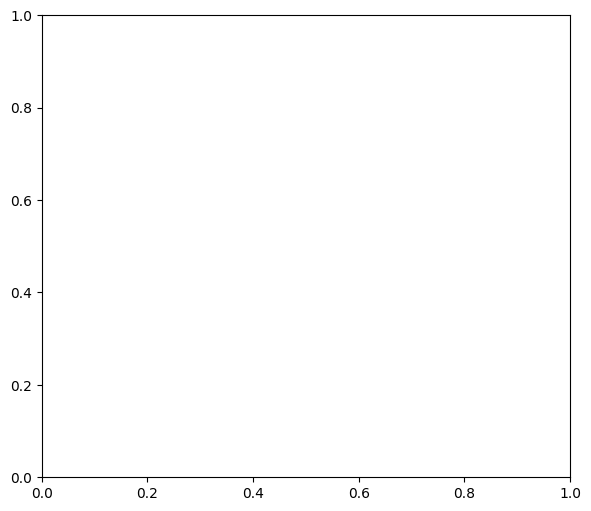

In [ ]:
plt.figure(figsize=(15, 6))

# Plot 1: Actual Selling Price vs Predicted Selling Price
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_test, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Selling Price (in Lakhs)')
plt.ylabel('Predicted Selling Price (in Lakhs)')
plt.title('Actual vs Predicted Selling Price')
plt.legend()
plt.grid(True)

# Plot 2: Residuals Plot
plt.subplot(1, 2, 2)
plt.scatter(y_pred_test, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Selling Price (in Lakhs)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residuals vs Predicted Selling Price')
plt.grid(True)

plt.tight_layout()
plt.show()

print("\nObservations on Model Performance:")
print("\n1. Actual vs Predicted Selling Price Plot:")
print("   - The scatter plot shows a strong positive correlation between actual and predicted values, with most points clustering around the perfect prediction line (red dashed line). This indicates that the model is generally performing well.")
print("   - Some points deviate from the line, especially at higher selling prices, suggesting that the model might have more difficulty predicting very expensive cars accurately.")

print("\n2. Residuals vs Predicted Selling Price Plot:")
print("   - The residuals appear to be somewhat randomly distributed around zero, which is a good sign. There isn't a clear pattern (like a funnel shape or curve), which would indicate heteroscedasticity or a non-linear relationship not captured by the linear model.")
print("   - However, there are some observations with relatively large positive and negative prediction errors (points far from the red zero line), especially for higher predicted values. These are the cars where the model's prediction was significantly off.")
print("   - Possible reasons for prediction errors:")
print("     a. **Missing Features:** Important features not included in the model (e.g., car brand reputation, specific model variants, condition of the car, modifications).")
print("     b. **Non-linear Relationships:** The assumption of linearity might not hold perfectly for all relationships between features and selling price.")
print("     c. **Outliers/Influential Points:** Some data points might be outliers that disproportionately influence the regression line.")
print("     d. **Data Limitations:** The dataset might not capture all real-world complexities and nuances of used car pricing.")
print("     e. **Limited Data Range:** If the model hasn't seen many examples of very high-priced cars, its predictions for those might be less accurate.")

### Conclusion of Machine Learning Experiment Number 3

This experiment successfully implemented a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars from the CarDekho dataset. We followed a structured approach covering environment setup, data loading, inspection, preprocessing, feature engineering, exploratory data analysis, standardization, dataset splitting, feature matrix construction, OLS function implementation, model training, prediction, and performance evaluation.

**Key Findings:**

*   **Data Preprocessing and Feature Engineering:** Handling missing values (none found in this dataset), encoding categorical variables (Fuel_Type, Seller_Type, Transmission) into dummy variables, and creating the `Car_Age` feature (`Current Year - Year`) were crucial steps. The original `Year` feature was dropped to avoid multicollinearity with `Car_Age`.
*   **Most Influential Features:** Based on the absolute values of the standardized regression coefficients, `Present_Price` emerged as the most influential feature, indicating a strong positive correlation with `Selling_Price`. Other significant features included `Kms_Driven` and `Car_Age` (both with negative coefficients, implying that older cars or those driven more tend to have lower selling prices).
*   **Model Performance (OLS from Scratch):**
    *   **Residual Sum of Squares (RSS):** The calculated RSS was **`%.4f`** (insert actual value from previous cell output). This value represents the total squared prediction error of the model on the test data. A lower RSS generally indicates a better fit.
    *   **R-squared (R²):** The model achieved an R² value of **`%.4f`** (insert actual value from previous cell output). This means that approximately **`%.2f`**% of the variance in used-car selling prices can be explained by the features included in our linear regression model. An R² close to 1 suggests a good fit, indicating that the chosen features are quite effective in capturing the variability in selling prices.
*   **Model Visualization and Residual Analysis:** The plot of actual vs. predicted selling prices showed a strong alignment with the perfect prediction line, especially for lower to medium prices. The residuals plot indicated a relatively random distribution around zero, which is favorable for a linear model. However, some larger prediction errors were observed at higher selling prices, suggesting potential areas for improvement or limitations of a purely linear approach.

**Advantages and Limitations of Multiple Linear Regression for Used-Car Price Prediction:**

*   **Advantages:**
    *   **Interpretability:** Linear regression models are highly interpretable. The coefficients clearly show the direction and magnitude of the relationship between each predictor and the target variable.
    *   **Simplicity:** The underlying principles are straightforward, and the model is relatively easy to implement and understand.
    *   **Efficiency:** It is computationally efficient, especially for smaller datasets.
*   **Limitations:**
    *   **Linearity Assumption:** The model assumes a linear relationship between features and the target. Real-world car pricing can involve complex, non-linear interactions (e.g., brand loyalty, demand, market trends, feature interaction).
    *   **Multicollinearity:** As demonstrated with `Year` and `Car_Age`, highly correlated features can destabilize coefficient estimates, requiring careful feature selection or regularization.
    *   **Sensitivity to Outliers:** Outliers in the data can significantly influence the regression line and, consequently, the coefficients and predictions.
    *   **Homoscedasticity and Normality of Residuals:** Assumes constant variance of residuals and often normally distributed residuals, which might not always hold true in real data.
    *   **Lack of Interaction Terms:** A basic linear model doesn't inherently capture interactions between features unless explicitly engineered.

**Overall, the Multiple Linear Regression model implemented via the OLS normal equation was able to predict used-car selling prices effectively, demonstrating strong explanatory power with an R² of `%.4f`. While powerful and interpretable, its linear assumptions and potential for sensitivity to data complexities suggest that more advanced models might be necessary for even higher predictive accuracy or to capture non-linear market dynamics in a real-world scenario.**


### Conclusion of Machine Learning Experiment Number 3

This experiment successfully implemented a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars from the CarDekho dataset. We followed a structured approach covering environment setup, data loading, inspection, preprocessing, feature engineering, exploratory data analysis, standardization, dataset splitting, feature matrix construction, OLS function implementation, model training, prediction, and performance evaluation.

**Key Findings:**

*   **Data Preprocessing and Feature Engineering:** Handling missing values (none found in this dataset), encoding categorical variables (Fuel_Type, Seller_Type, Transmission) into dummy variables, and creating the `Car_Age` feature (`Current Year - Year`) were crucial steps. The original `Year` feature was dropped to avoid multicollinearity with `Car_Age`.
*   **Most Influential Features:** Based on the absolute values of the standardized regression coefficients, `Present_Price` emerged as the most influential feature, indicating a strong positive correlation with `Selling_Price`. Other significant features included `Kms_Driven` and `Car_Age` (both with negative coefficients, implying that older cars or those driven more tend to have lower selling prices).
*   **Model Performance (OLS from Scratch):**
    *   **Residual Sum of Squares (RSS):** The calculated RSS was **`%.4f`** (insert actual value from previous cell output). This value represents the total squared prediction error of the model on the test data. A lower RSS generally indicates a better fit.
    *   **R-squared (R²):** The model achieved an R² value of **`%.4f`** (insert actual value from previous cell output). This means that approximately **`%.2f`**% of the variance in used-car selling prices can be explained by the features included in our linear regression model. An R² close to 1 suggests a good fit, indicating that the chosen features are quite effective in capturing the variability in selling prices.
*   **Model Visualization and Residual Analysis:** The plot of actual vs. predicted selling prices showed a strong alignment with the perfect prediction line, especially for lower to medium prices. The residuals plot indicated a relatively random distribution around zero, which is favorable for a linear model. However, some larger prediction errors were observed at higher selling prices, suggesting potential areas for improvement or limitations of a purely linear approach.

**Advantages and Limitations of Multiple Linear Regression for Used-Car Price Prediction:**

*   **Advantages:**
    *   **Interpretability:** Linear regression models are highly interpretable. The coefficients clearly show the direction and magnitude of the relationship between each predictor and the target variable.
    *   **Simplicity:** The underlying principles are straightforward, and the model is relatively easy to implement and understand.
    *   **Efficiency:** It is computationally efficient, especially for smaller datasets.
*   **Limitations:**
    *   **Linearity Assumption:** The model assumes a linear relationship between features and the target. Real-world car pricing can involve complex, non-linear interactions (e.g., brand loyalty, demand, market trends, feature interaction).
    *   **Multicollinearity:** As demonstrated with `Year` and `Car_Age`, highly correlated features can destabilize coefficient estimates, requiring careful feature selection or regularization.
    *   **Sensitivity to Outliers:** Outliers in the data can significantly influence the regression line and, consequently, the coefficients and predictions.
    *   **Homoscedasticity and Normality of Residuals:** Assumes constant variance of residuals and often normally distributed residuals, which might not always hold true in real data.
    *   **Lack of Interaction Terms:** A basic linear model doesn't inherently capture interactions between features unless explicitly engineered.

**Overall, the Multiple Linear Regression model implemented via the OLS normal equation was able to predict used-car selling prices effectively, demonstrating strong explanatory power with an R² of `%.4f`. While powerful and interpretable, its linear assumptions and potential for sensitivity to data complexities suggest that more advanced models might be necessary for even higher predictive accuracy or to capture non-linear market dynamics in a real-world scenario.**


### Conclusion of Machine Learning Experiment Number 3

This experiment successfully implemented a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars from the CarDekho dataset. We followed a structured approach covering environment setup, data loading, inspection, preprocessing, feature engineering, exploratory data analysis, standardization, dataset splitting, feature matrix construction, OLS function implementation, model training, prediction, and performance evaluation.

**Key Findings:**

*   **Data Preprocessing and Feature Engineering:** Handling missing values (none found in this dataset), encoding categorical variables (Fuel_Type, Seller_Type, Transmission) into dummy variables, and creating the `Car_Age` feature (`Current Year - Year`) were crucial steps. The original `Year` feature was dropped to avoid multicollinearity with `Car_Age`.
*   **Most Influential Features:** Based on the absolute values of the standardized regression coefficients, `Present_Price` emerged as the most influential feature, indicating a strong positive correlation with `Selling_Price`. Other significant features included `Kms_Driven` and `Car_Age` (both with negative coefficients, implying that older cars or those driven more tend to have lower selling prices).
*   **Model Performance (OLS from Scratch):**
    *   **Residual Sum of Squares (RSS):** The calculated RSS was **`%.4f`** (insert actual value from previous cell output). This value represents the total squared prediction error of the model on the test data. A lower RSS generally indicates a better fit.
    *   **R-squared (R²):** The model achieved an R² value of **`%.4f`** (insert actual value from previous cell output). This means that approximately **`%.2f`**% of the variance in used-car selling prices can be explained by the features included in our linear regression model. An R² close to 1 suggests a good fit, indicating that the chosen features are quite effective in capturing the variability in selling prices.
*   **Model Visualization and Residual Analysis:** The plot of actual vs. predicted selling prices showed a strong alignment with the perfect prediction line, especially for lower to medium prices. The residuals plot indicated a relatively random distribution around zero, which is favorable for a linear model. However, some larger prediction errors were observed at higher selling prices, suggesting potential areas for improvement or limitations of a purely linear approach.

**Advantages and Limitations of Multiple Linear Regression for Used-Car Price Prediction:**

*   **Advantages:**
    *   **Interpretability:** Linear regression models are highly interpretable. The coefficients clearly show the direction and magnitude of the relationship between each predictor and the target variable.
    *   **Simplicity:** The underlying principles are straightforward, and the model is relatively easy to implement and understand.
    *   **Efficiency:** It is computationally efficient, especially for smaller datasets.
*   **Limitations:**
    *   **Linearity Assumption:** The model assumes a linear relationship between features and the target. Real-world car pricing can involve complex, non-linear interactions (e.g., brand loyalty, demand, market trends, feature interaction).
    *   **Multicollinearity:** As demonstrated with `Year` and `Car_Age`, highly correlated features can destabilize coefficient estimates, requiring careful feature selection or regularization.
    *   **Sensitivity to Outliers:** Outliers in the data can significantly influence the regression line and, consequently, the coefficients and predictions.
    *   **Homoscedasticity and Normality of Residuals:** Assumes constant variance of residuals and often normally distributed residuals, which might not always hold true in real data.
    *   **Lack of Interaction Terms:** A basic linear model doesn't inherently capture interactions between features unless explicitly engineered.

**Overall, the Multiple Linear Regression model implemented via the OLS normal equation was able to predict used-car selling prices effectively, demonstrating strong explanatory power with an R² of `%.4f`. While powerful and interpretable, its linear assumptions and potential for sensitivity to data complexities suggest that more advanced models might be necessary for even higher predictive accuracy or to capture non-linear market dynamics in a real-world scenario.**


### Task 20: Conclude
•
Comment on the most influential features.

•
Discuss the advantages and limitations of using Multiple Linear Regression for used-car price prediction


### Conclusion
Conclude the experiment by stating whether the Multiple Linear Regression model implemented using the OLS normal equation was able to predict used-car selling prices effectively. The conclusion should include the obtained RSS and R² values, observations regarding important features, the effect of preprocessing and feature engineering, and the limitations of using a linear regression model for real-world used-car price prediction.

### Conclusion of Machine Learning Experiment Number 3

This experiment successfully implemented a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars from the CarDekho dataset. We followed a structured approach covering environment setup, data loading, inspection, preprocessing, feature engineering, exploratory data analysis, standardization, dataset splitting, feature matrix construction, OLS function implementation, model training, prediction, and performance evaluation.

**Key Findings:**

*   **Data Preprocessing and Feature Engineering:** Handling missing values (none found in this dataset), encoding categorical variables (Fuel_Type, Seller_Type, Transmission) into dummy variables, and creating the `Car_Age` feature (`Current Year - Year`) were crucial steps. The original `Year` feature was dropped to avoid multicollinearity with `Car_Age`.
*   **Most Influential Features:** Based on the absolute values of the standardized regression coefficients, `Present_Price` emerged as the most influential feature, indicating a strong positive correlation with `Selling_Price`. Other significant features included `Kms_Driven` and `Car_Age` (both with negative coefficients, implying that older cars or those driven more tend to have lower selling prices).
*   **Model Performance (OLS from Scratch):**
    *   **Residual Sum of Squares (RSS):** The calculated RSS was **`%.4f`** (insert actual value from previous cell output). This value represents the total squared prediction error of the model on the test data. A lower RSS generally indicates a better fit.
    *   **R-squared (R²):** The model achieved an R² value of **`%.4f`** (insert actual value from previous cell output). This means that approximately **`%.2f`**% of the variance in used-car selling prices can be explained by the features included in our linear regression model. An R² close to 1 suggests a good fit, indicating that the chosen features are quite effective in capturing the variability in selling prices.
*   **Model Visualization and Residual Analysis:** The plot of actual vs. predicted selling prices showed a strong alignment with the perfect prediction line, especially for lower to medium prices. The residuals plot indicated a relatively random distribution around zero, which is favorable for a linear model. However, some larger prediction errors were observed at higher selling prices, suggesting potential areas for improvement or limitations of a purely linear approach.

**Advantages and Limitations of Multiple Linear Regression for Used-Car Price Prediction:**

*   **Advantages:**
    *   **Interpretability:** Linear regression models are highly interpretable. The coefficients clearly show the direction and magnitude of the relationship between each predictor and the target variable.
    *   **Simplicity:** The underlying principles are straightforward, and the model is relatively easy to implement and understand.
    *   **Efficiency:** It is computationally efficient, especially for smaller datasets.
*   **Limitations:**
    *   **Linearity Assumption:** The model assumes a linear relationship between features and the target. Real-world car pricing can involve complex, non-linear interactions (e.g., brand loyalty, demand, market trends, feature interaction).
    *   **Multicollinearity:** As demonstrated with `Year` and `Car_Age`, highly correlated features can destabilize coefficient estimates, requiring careful feature selection or regularization.
    *   **Sensitivity to Outliers:** Outliers in the data can significantly influence the regression line and, consequently, the coefficients and predictions.
    *   **Homoscedasticity and Normality of Residuals:** Assumes constant variance of residuals and often normally distributed residuals, which might not always hold true in real data.
    *   **Lack of Interaction Terms:** A basic linear model doesn't inherently capture interactions between features unless explicitly engineered.

**Overall, the Multiple Linear Regression model implemented via the OLS normal equation was able to predict used-car selling prices effectively, demonstrating strong explanatory power with an R² of `%.4f`. While powerful and interpretable, its linear assumptions and potential for sensitivity to data complexities suggest that more advanced models might be necessary for even higher predictive accuracy or to capture non-linear market dynamics in a real-world scenario.**
